In [ ]:
from google.colab import drive

drive.mount('/content/drive')


%cd /content/drive/MyDrive/images/geometric shapes dataset
%ls

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/images/geometric shapes dataset
Circle/  Square/  Triangle/


Uspostavljanje veze s Google Drivom kako bi se preuzeo skup podataka.

In [ ]:
!ls

Circle	Square	Triangle


Skup podataka sastoji se od 3 podmape pri čemu svaka podmapa predstavlja zasebnu kategoriju slika.

In [ ]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
import os

Učitvanje potrebnih biblioteka za rad.

In [ ]:
path = '/content/drive/MyDrive/images/geometric shapes dataset'
pictures = []

labels = []

maps = ['Circle', 'Square', 'Triangle']


def load_pictures(path, maps):
  global pictures, labels
  pictures = []
  labels = []

  for map in maps:
    path_class = os.path.join(path, map)

    counter = 0

    for name in os.listdir(path_class):

      if counter >= 30:
        break
      picture_path = os.path.join(path_class, name)
      slika = cv.imread(picture_path, cv.IMREAD_COLOR_RGB)

      if slika is not None:
        pictures.append(slika)
        labels.append(map)
        counter += 1



load_pictures(path, maps)
print(f"Ukupno učitano slika: {len(pictures)}")
print(f"Klase: {set(labels)}")



Ukupno učitano slika: 90
Klase: {'Triangle', 'Circle', 'Square'}


Evo prijedlog komentara koji možeš staviti iznad ili ispod ove ćelije, u istom stilu kao prethodni:
Verzija u tvom stilu:

Definirana je funkcija za učitavanje određenog broja slika iz svake kategorije. Učitan je jednak broj uzoraka svake klase te su slike spremljene u listu u RGB formatu, dok su odgovarajuće oznake kategorije za svaku sliku spremljene u listu labels.

In [ ]:
original_pictures = [img.copy() for img in pictures]

Kopiranje slika kako bi se sačuvale izvorne slike za daljnu analizu.

In [ ]:
pictures = [cv.cvtColor(s, cv.COLOR_RGB2GRAY) for s in pictures]
pictures1 = pictures.copy()

Pretvorba slika iz RGB formata u Grayscale format.

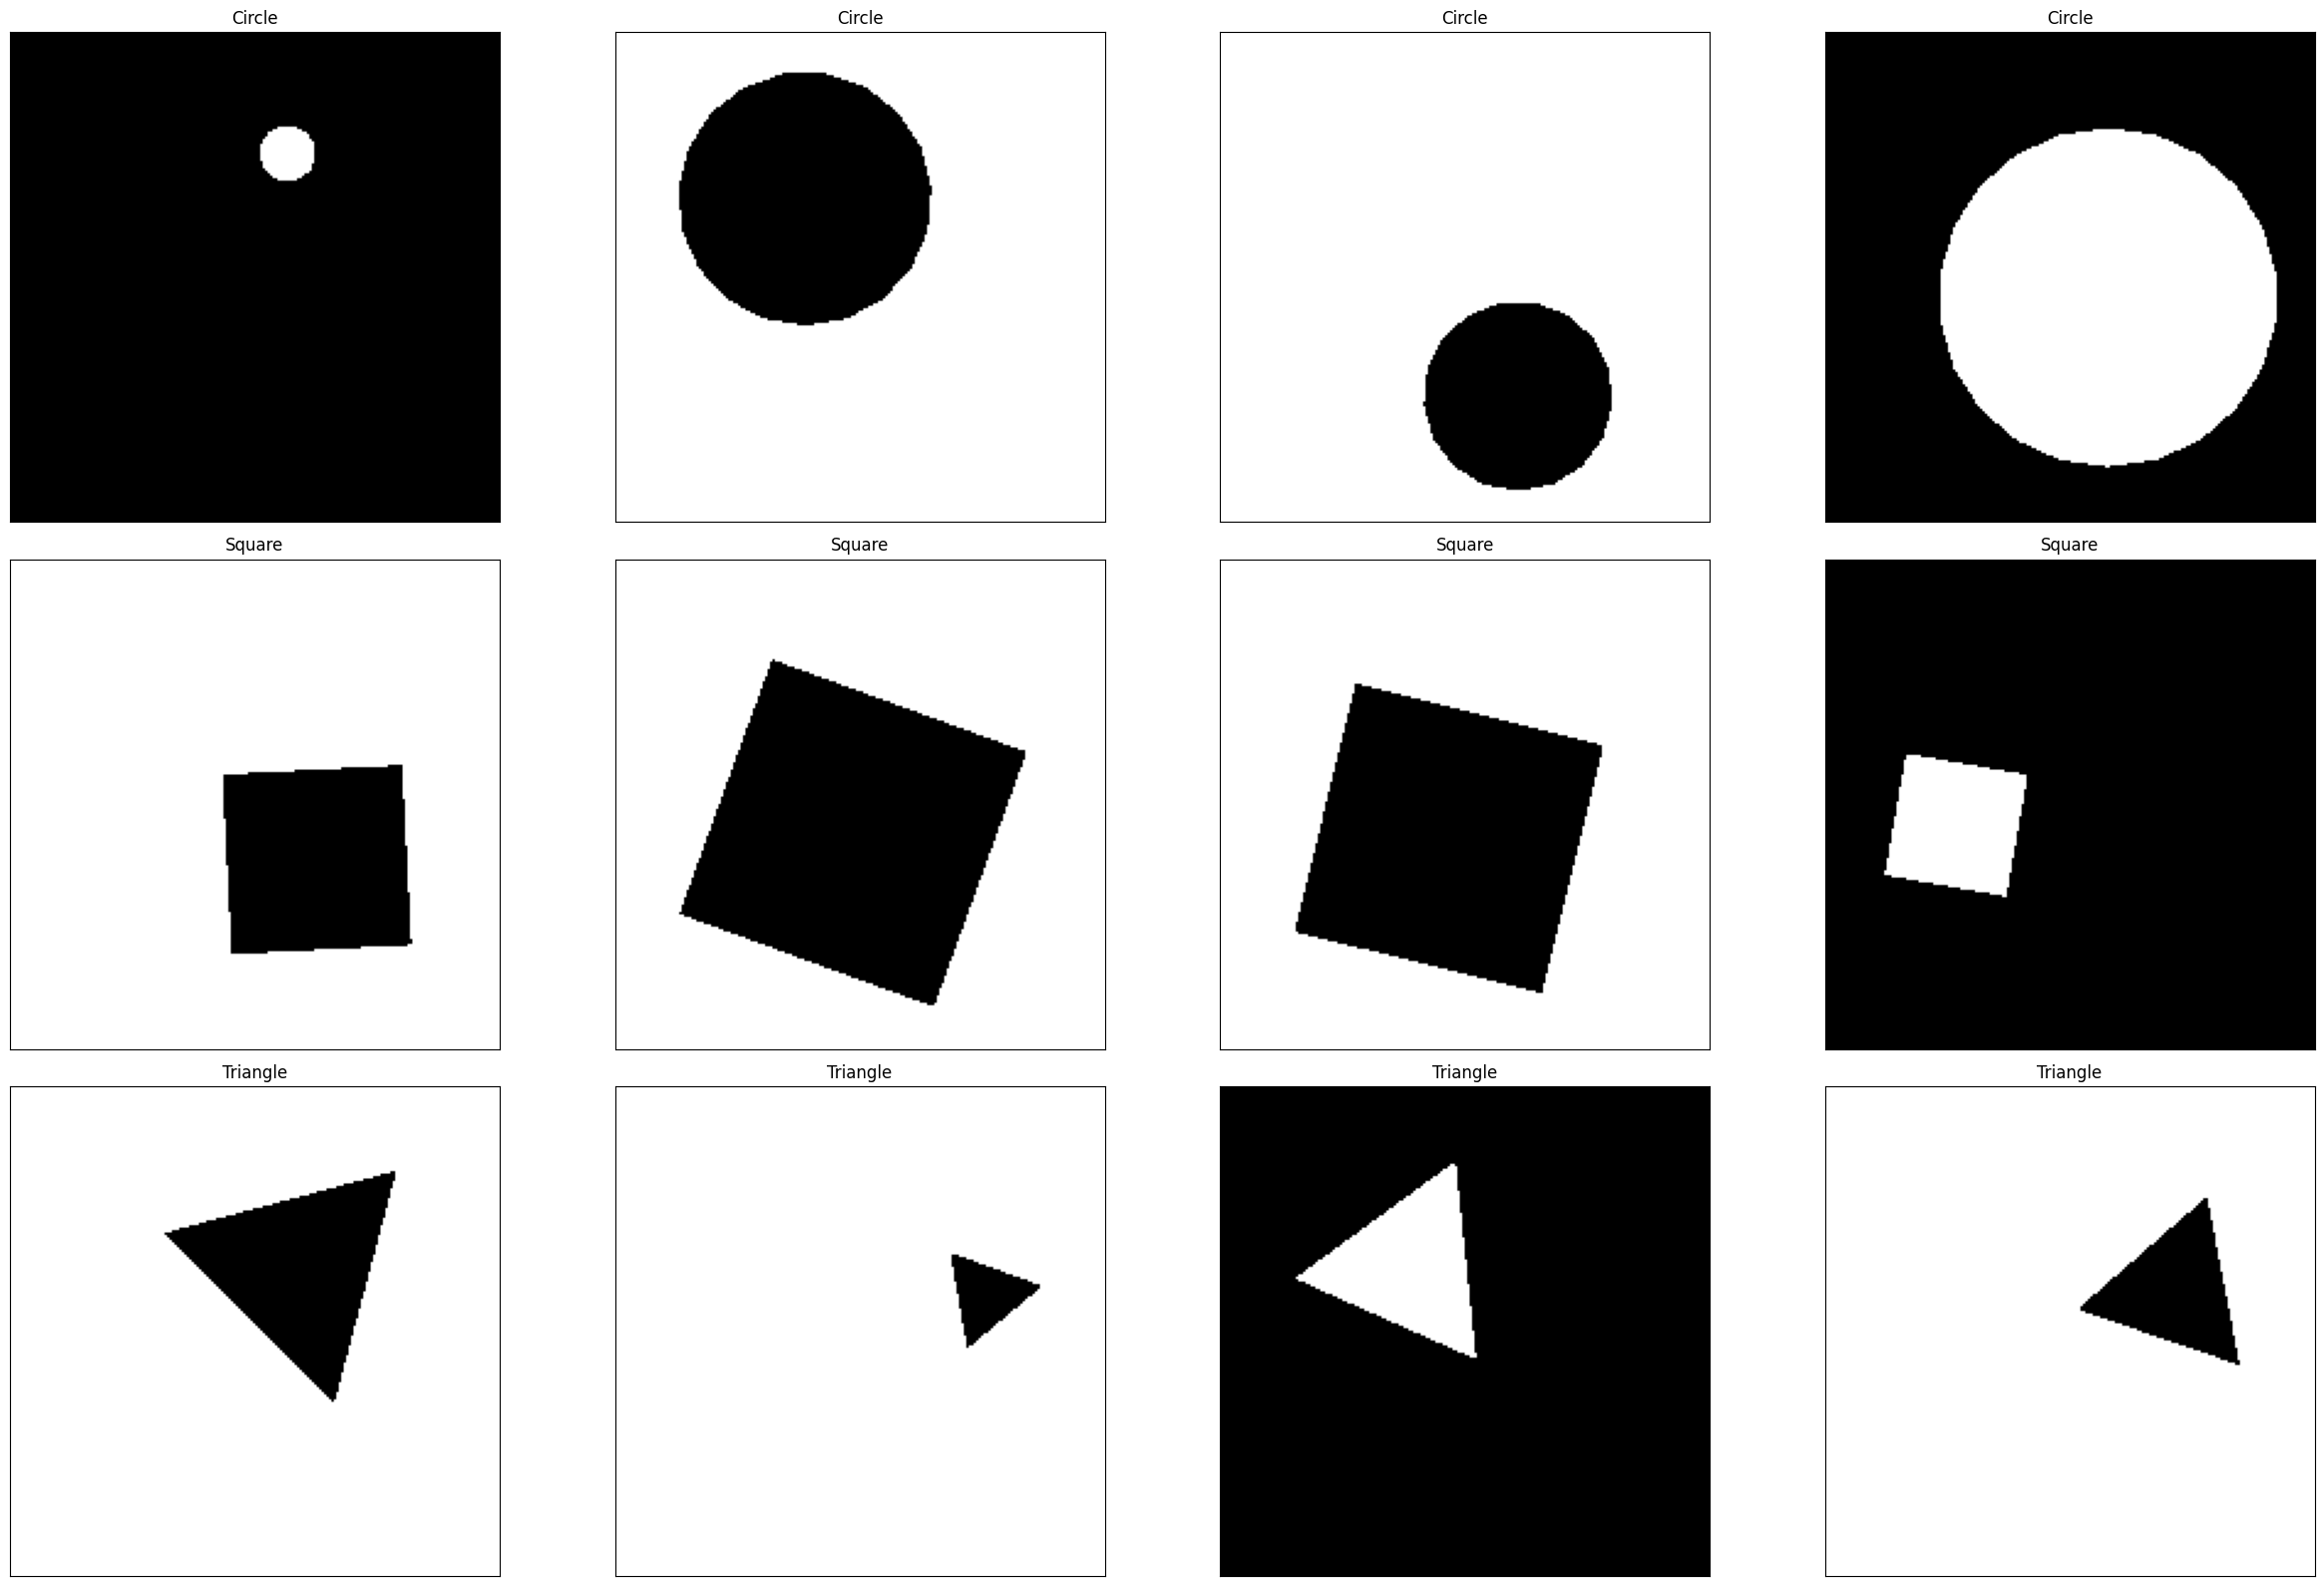

In [ ]:
def show_samples(pictures):
    plt.figure(figsize=(25, 16))

    num_categories = len(maps)

    plot_index = 1

    for klasa in maps:
        klasa_slike = [pictures[i] for i in range(len(pictures)) if labels[i] == klasa]

        for j in range(4):
            plt.subplot(num_categories, 4, plot_index)
            plt.imshow(klasa_slike[j], cmap='gray')
            plt.title(klasa)
            plt.xticks([])
            plt.yticks([])
            plot_index += 1

    plt.tight_layout()
    plt.show()

show_samples(pictures)

Definirana je funkcija za prikaz uzoraka slika svake kategorije kako bi se vizualno prikazao izgled slika unutar skupa podataka. Za svaku klasu prikazano je po 4 slike, poredane u zasebne redove.



In [ ]:
print(pictures[0].shape)
print('\n', labels[0])

(200, 200)

 Circle


Sve slike su dimenzija 200 s 200.

In [ ]:
def otsu_binarize():

  for i in range(len(pictures)):
    prag, binary_picture = cv.threshold(pictures[i], 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

    pictures[i] = binary_picture

otsu_binarize()


Definirana je funkcija za binarizaciju slika pomoću Otsu metode, koja automatski određuje optimalni prag za razdvajanje piksela na crne i bijele odnosno na 0 i 255.

In [ ]:
def black_background():

  for i in range(len(pictures)):
    h, w = pictures[i].shape
    kut_gore_lijevo  = int(pictures[i][10, 10])
    kut_gore_desno   = int(pictures[i][20, w - 20])
    kut_dolje_lijevo  = int(pictures[i][h - 20, 20])
    kut_dolje_desno   = int(pictures[i][h - 20, w - 20])

    prosjek_kutova = (kut_gore_lijevo + kut_gore_desno + kut_dolje_lijevo + kut_dolje_desno) / 4

    if prosjek_kutova > 127:
      pictures[i] = cv.bitwise_not(pictures[i])










Definirana je funkcija za inverziju slika kojom se standardizira prikaz tako da pozadina uvijek bude crna, a objekt bijele boje. Inverzija se primjenjuje samo nad slikama kod kojih je boja pozadine i objekta suprotna od željene. Kako bi se utvrdila boja pozadine, uzimaju se u obzir pikseli u krajnjim kutovima slike s određenim pomakom od ruba te se računa njihov prosjek. Ukoliko je prosjek veći od 127, znači da je pozadina bijela jer bijeli pikseli imaju intenzitet 255, pa se nad takvom slikom primjenjuje inverzija pomoću cv.bitwise_not.

In [ ]:
black_background()




Poziv funkcije za inverziju slika.

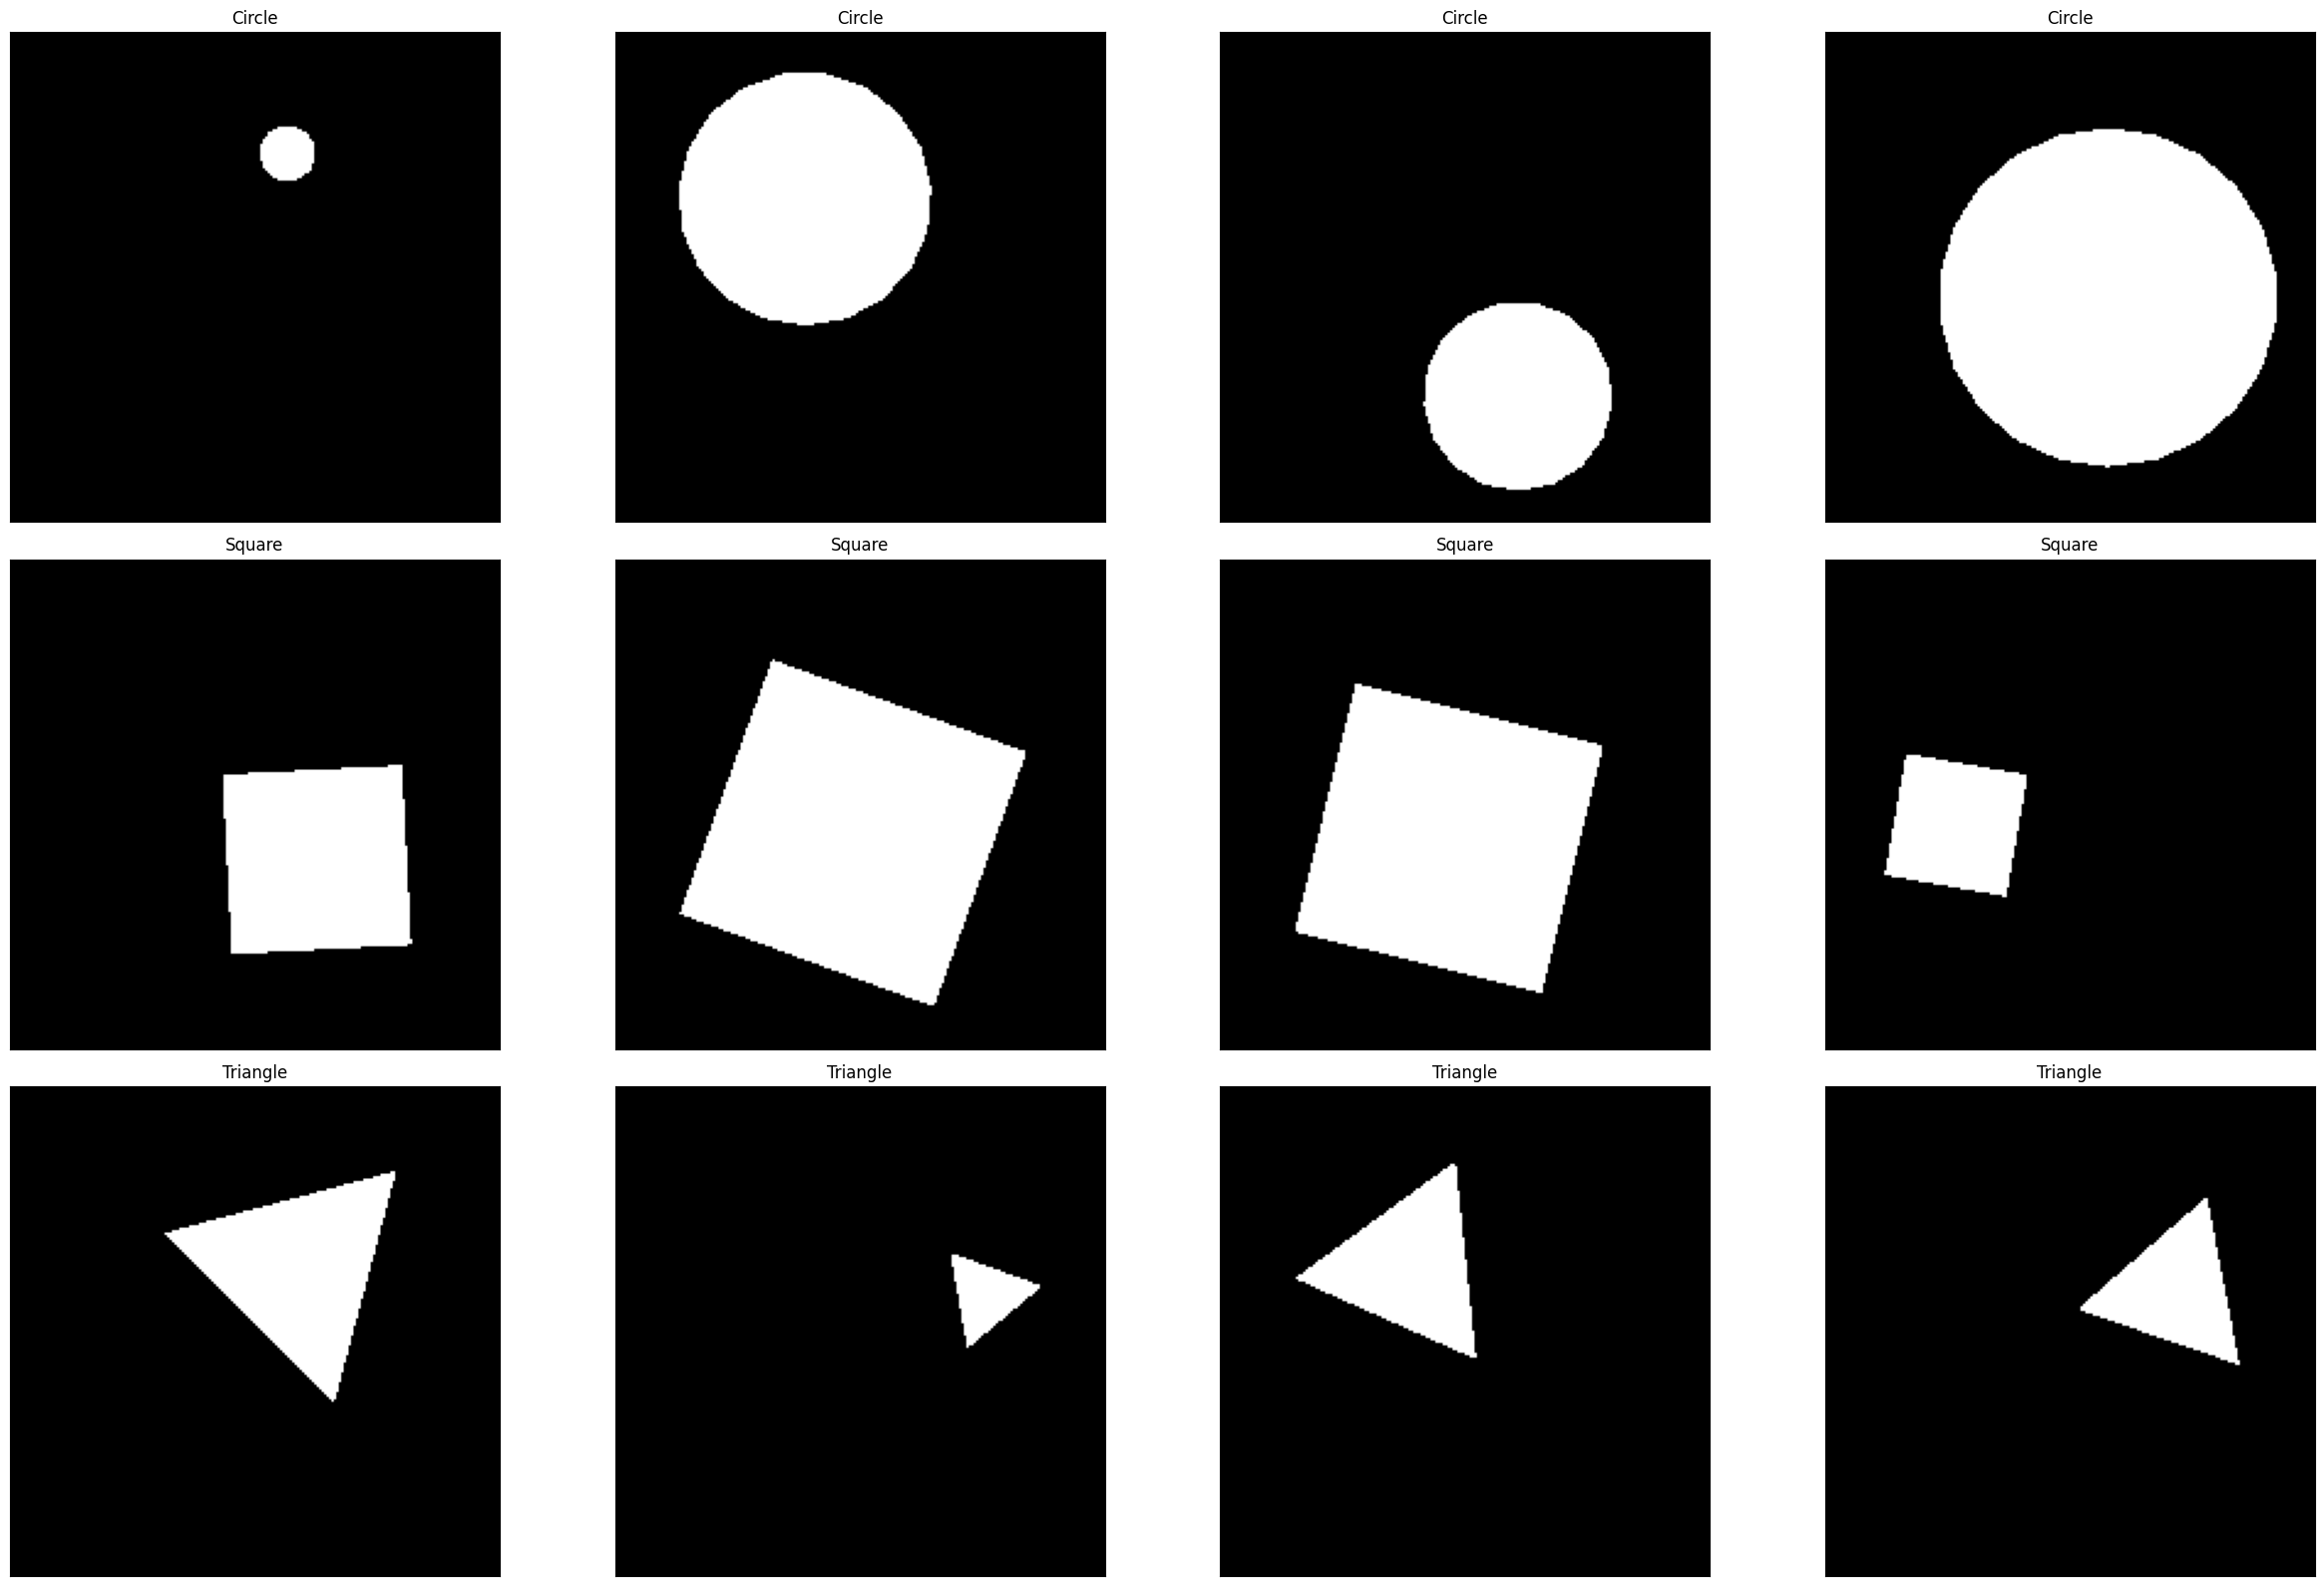

In [ ]:
show_samples(pictures)

Iz prikaza se vidi kako je funkcija uspješno otklonila problem i sada su sve slike jednake boje kao i objekti.

In [ ]:
import random

dimenzije = (200, 200)

for i in range(30):
    temp_img = np.zeros(dimenzije, dtype=np.uint8)

    w = random.randint(40, 100)
    h = int(w / random.uniform(1.4, 2.0))

    center_x = random.randint(w, dimenzije[1] - w)
    center_y = random.randint(h, dimenzije[0] - h)

    kut = random.uniform(0, 360)

    cv.rectangle(temp_img, (center_x - w//2, center_y - h//2),
                         (center_x + w//2, center_y + h//2), 255, -1)

    M = cv.getRotationMatrix2D((center_x, center_y), kut, 1.0)
    final_img = cv.warpAffine(temp_img, M, dimenzije)

    pictures.append(final_img)
    labels.append("Rectangle")

    final_rgb = cv.cvtColor(final_img, cv.COLOR_GRAY2RGB)
    original_pictures.append(final_rgb)

print("Dodano 30 pravokutnika")
print(f"Ukupno slika: {len(pictures)}")


Dodano 30 pravokutnika
Ukupno slika: 120


U ovom isječku koda generirane su umjetne slike pravokutnika, iz razloga što skup podataka sadrži samo 3 geometrijska oblika pa se dodavanjem četvrte klase pravokutnika omogućuje testiranje modela i na obliku koji nije bio dio originalnog skupa za treniranje.

Centar pravokutnika postavljen je nasumično, čime pravokutnici imaju nasumičnu poziciju na slici. Također, veličina pravokutnika je nasumična, ali je omjer stranica definiran unutar određenog raspona od 1.4 do 2.0 kako bi oblik zaista odgovarao pravokutniku, a ne kvadratu. Dodatno je primijenjena i nasumična rotacija pravokutnika za kut između 0 i 360 stupnjeva.

Također u kodu slike pravokutnika su spremljene u listu slika nad kojima ce biti primjenen daljni rad ali i spremljeni su u listu orginalnih slika.

In [ ]:
maps = np.unique(labels)
print(maps)

['Circle' 'Rectangle' 'Square' 'Triangle']


U varijabli maps su spremljene oznake kategorija.

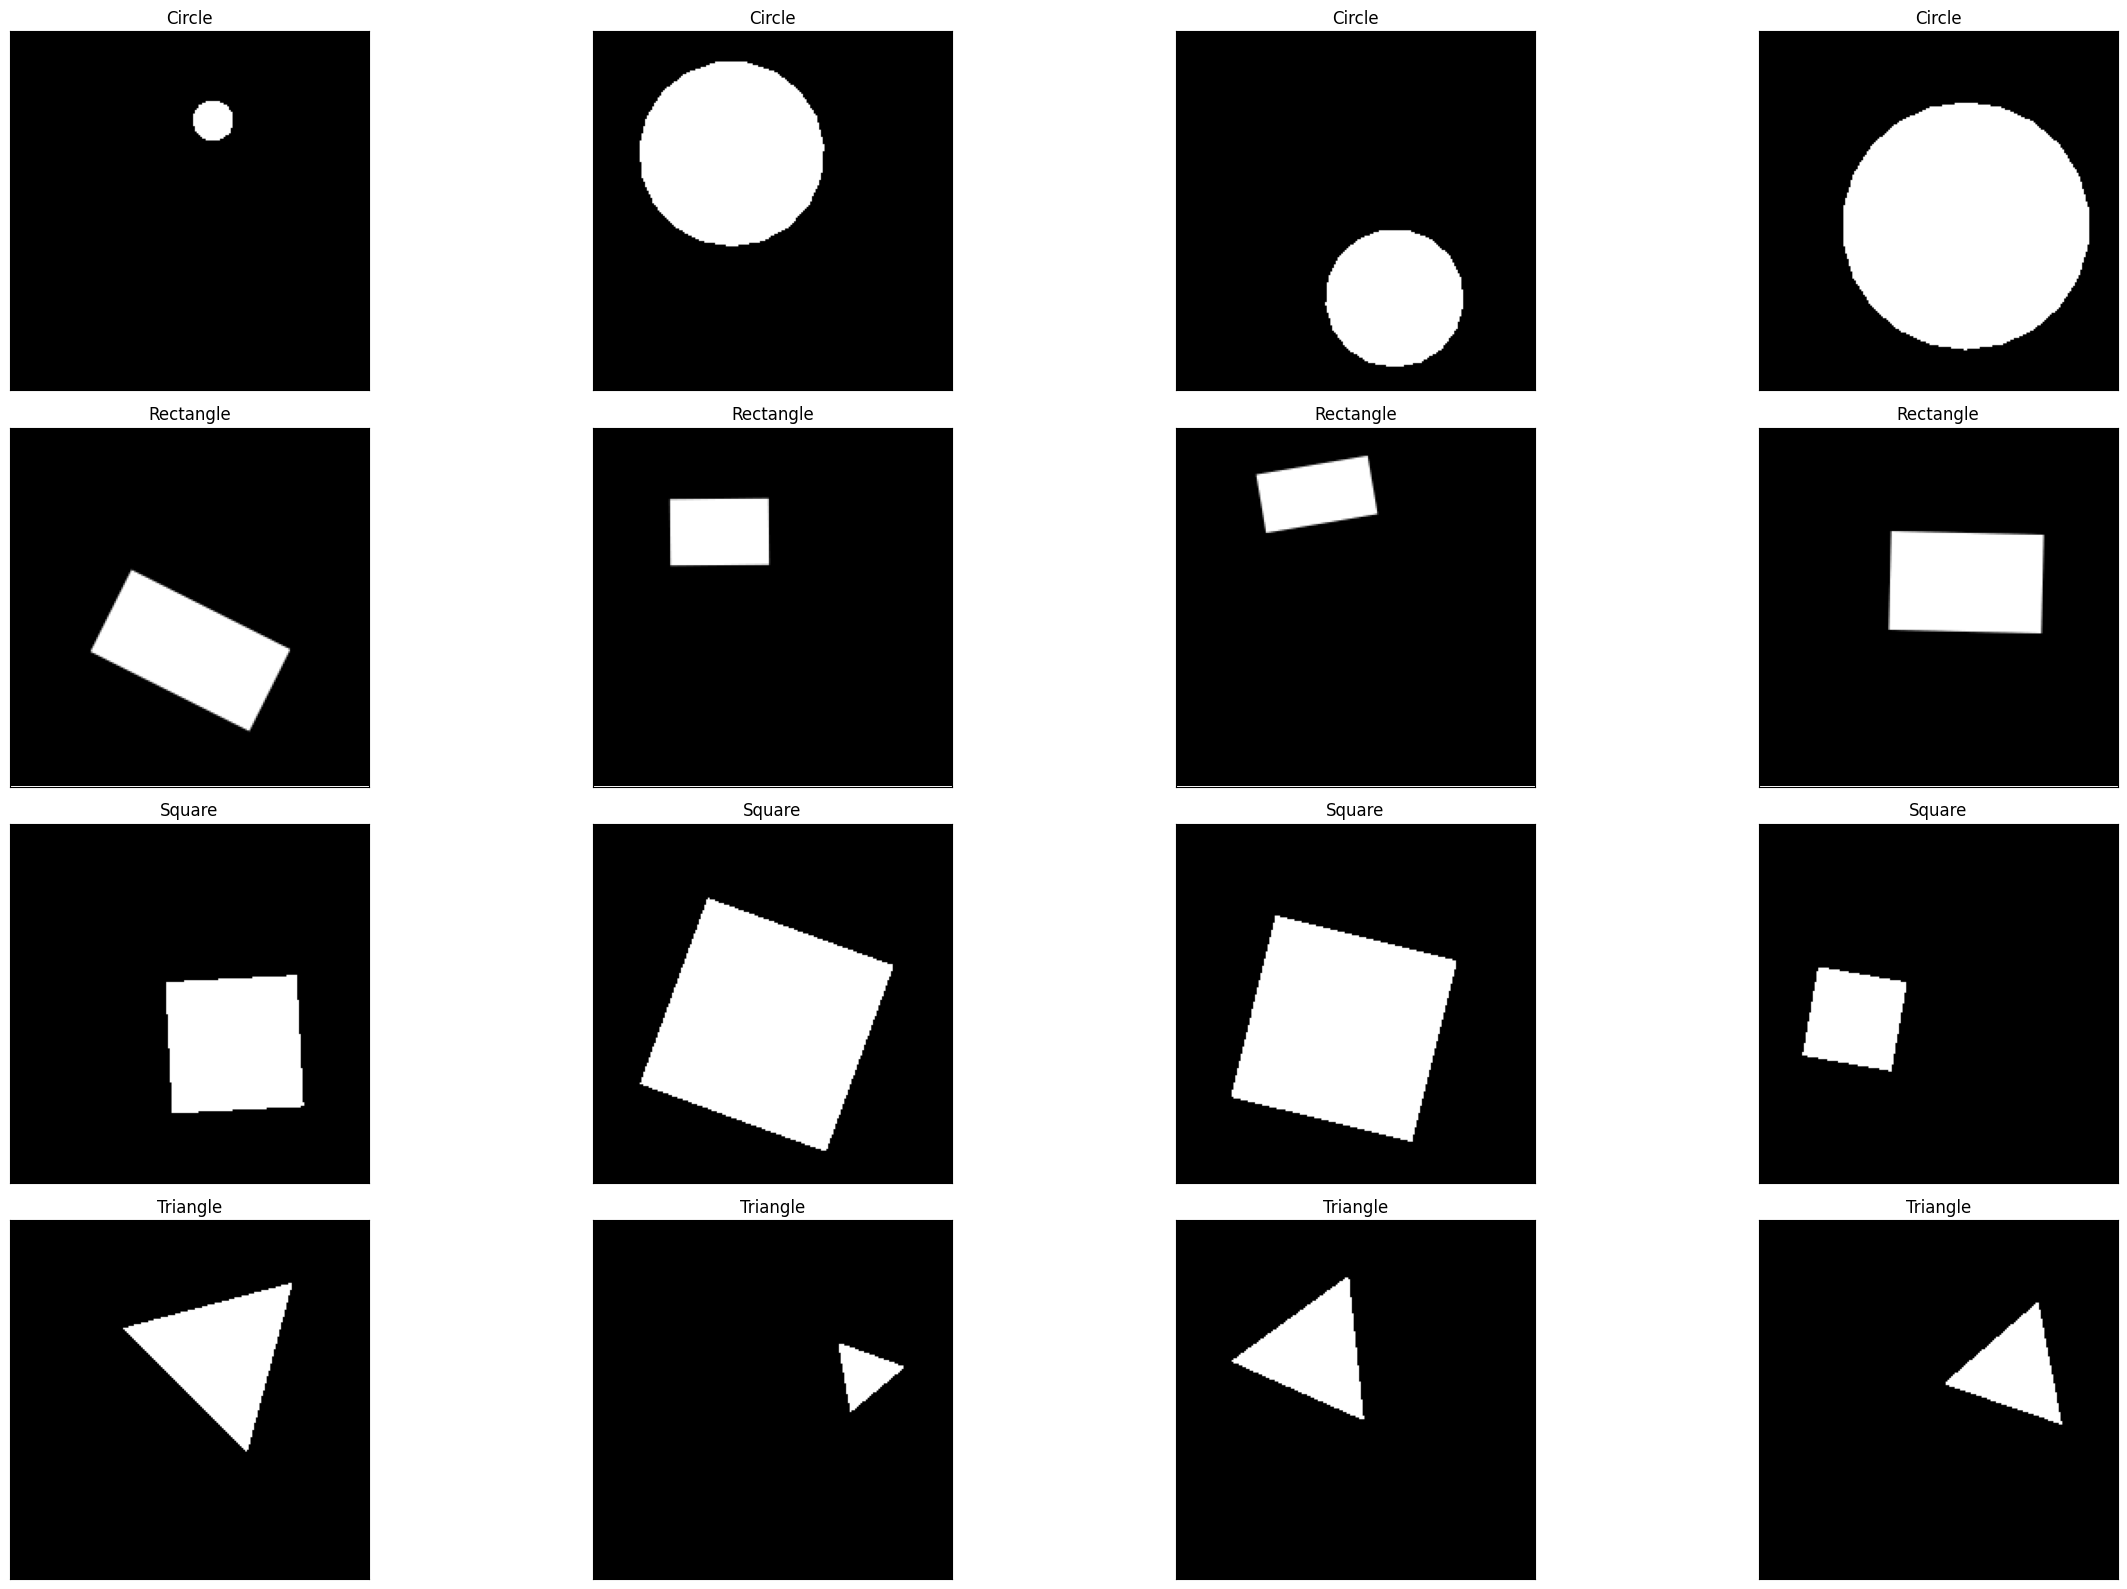

In [ ]:
show_samples(pictures)

U ovome dijelu su vizuano prikazani uzorci slika svake kateogrije gdje se vidi da su sada i prisutne slike pravokutnika.

In [ ]:
def add_noise():
  noise_pictures = []

  for i in range(len(pictures)):
    noisy_img = pictures[i].copy()

    white_pixel = np.argwhere(pictures[i] == 255)
    black_pixel = np.argwhere(pictures[i] == 0)

    if len(black_pixel) > 0:
      for j in range(10):

        n = np.random.randint(0, len(black_pixel))
        y, x = black_pixel[n]
        r = np.random.randint(1, 4)
        cv.circle(noisy_img, (x, y), r, 255, -1)

    if len(white_pixel) > 0:
      for k in range(12):
        n = np.random.randint(0, len(white_pixel))
        y, x =white_pixel[n]
        r = np.random.randint(3, 7)
        cv.circle(noisy_img, (x, y), r, 0, -1)

      for l in range(4):
        n = np.random.randint(0, len(white_pixel))
        y_s, x_s = white_pixel[n]
        dx = np.random.randint(-40, 40)
        dy = np.random.randint(-40, 40)
        debljina = np.random.randint(2, 5)
        cv.line(noisy_img, (x_s, y_s), (x_s + dx, y_s + dy), 0, debljina)





    noise_pictures.append(noisy_img)

  return noise_pictures




noise_pictures = add_noise()



Kako su slike idealne bez šumova u ovom dijelu je definirana funkcija za dodavanje šuma. Kako su slike u stvarnome svijetu podložne nepravilnostima i šumovima dodani su 3 oblika šuma. Na nasumičnim pozicijama nad pozadinom su dodane bijlee toke polumjera od 1 do 3 piksela. Na taj način cilj je bio simulirati pozadinski šum.

Na nasumično odabranim pozicijama unutar bijelih piksela odnosno samoga objekta dodani su crni kružići polumjera od 3 do 6 piksela kojima je cilj bio simulirati šumove koji stvaraju pukotine i nepravilnosti objekata.

Te kao 3. oblik su dodane crne linije nasumične duljine u rasponu od 40 piksela te su nasumičnog smijera i duljine.  Ove linije simuliraju ogrebotine ili prekide na objektu.

Cilj je bio sa simuliranim šumovima narušiti idealne geometrijske oblike kako bi se pokazale prednosti morfološki operacija.

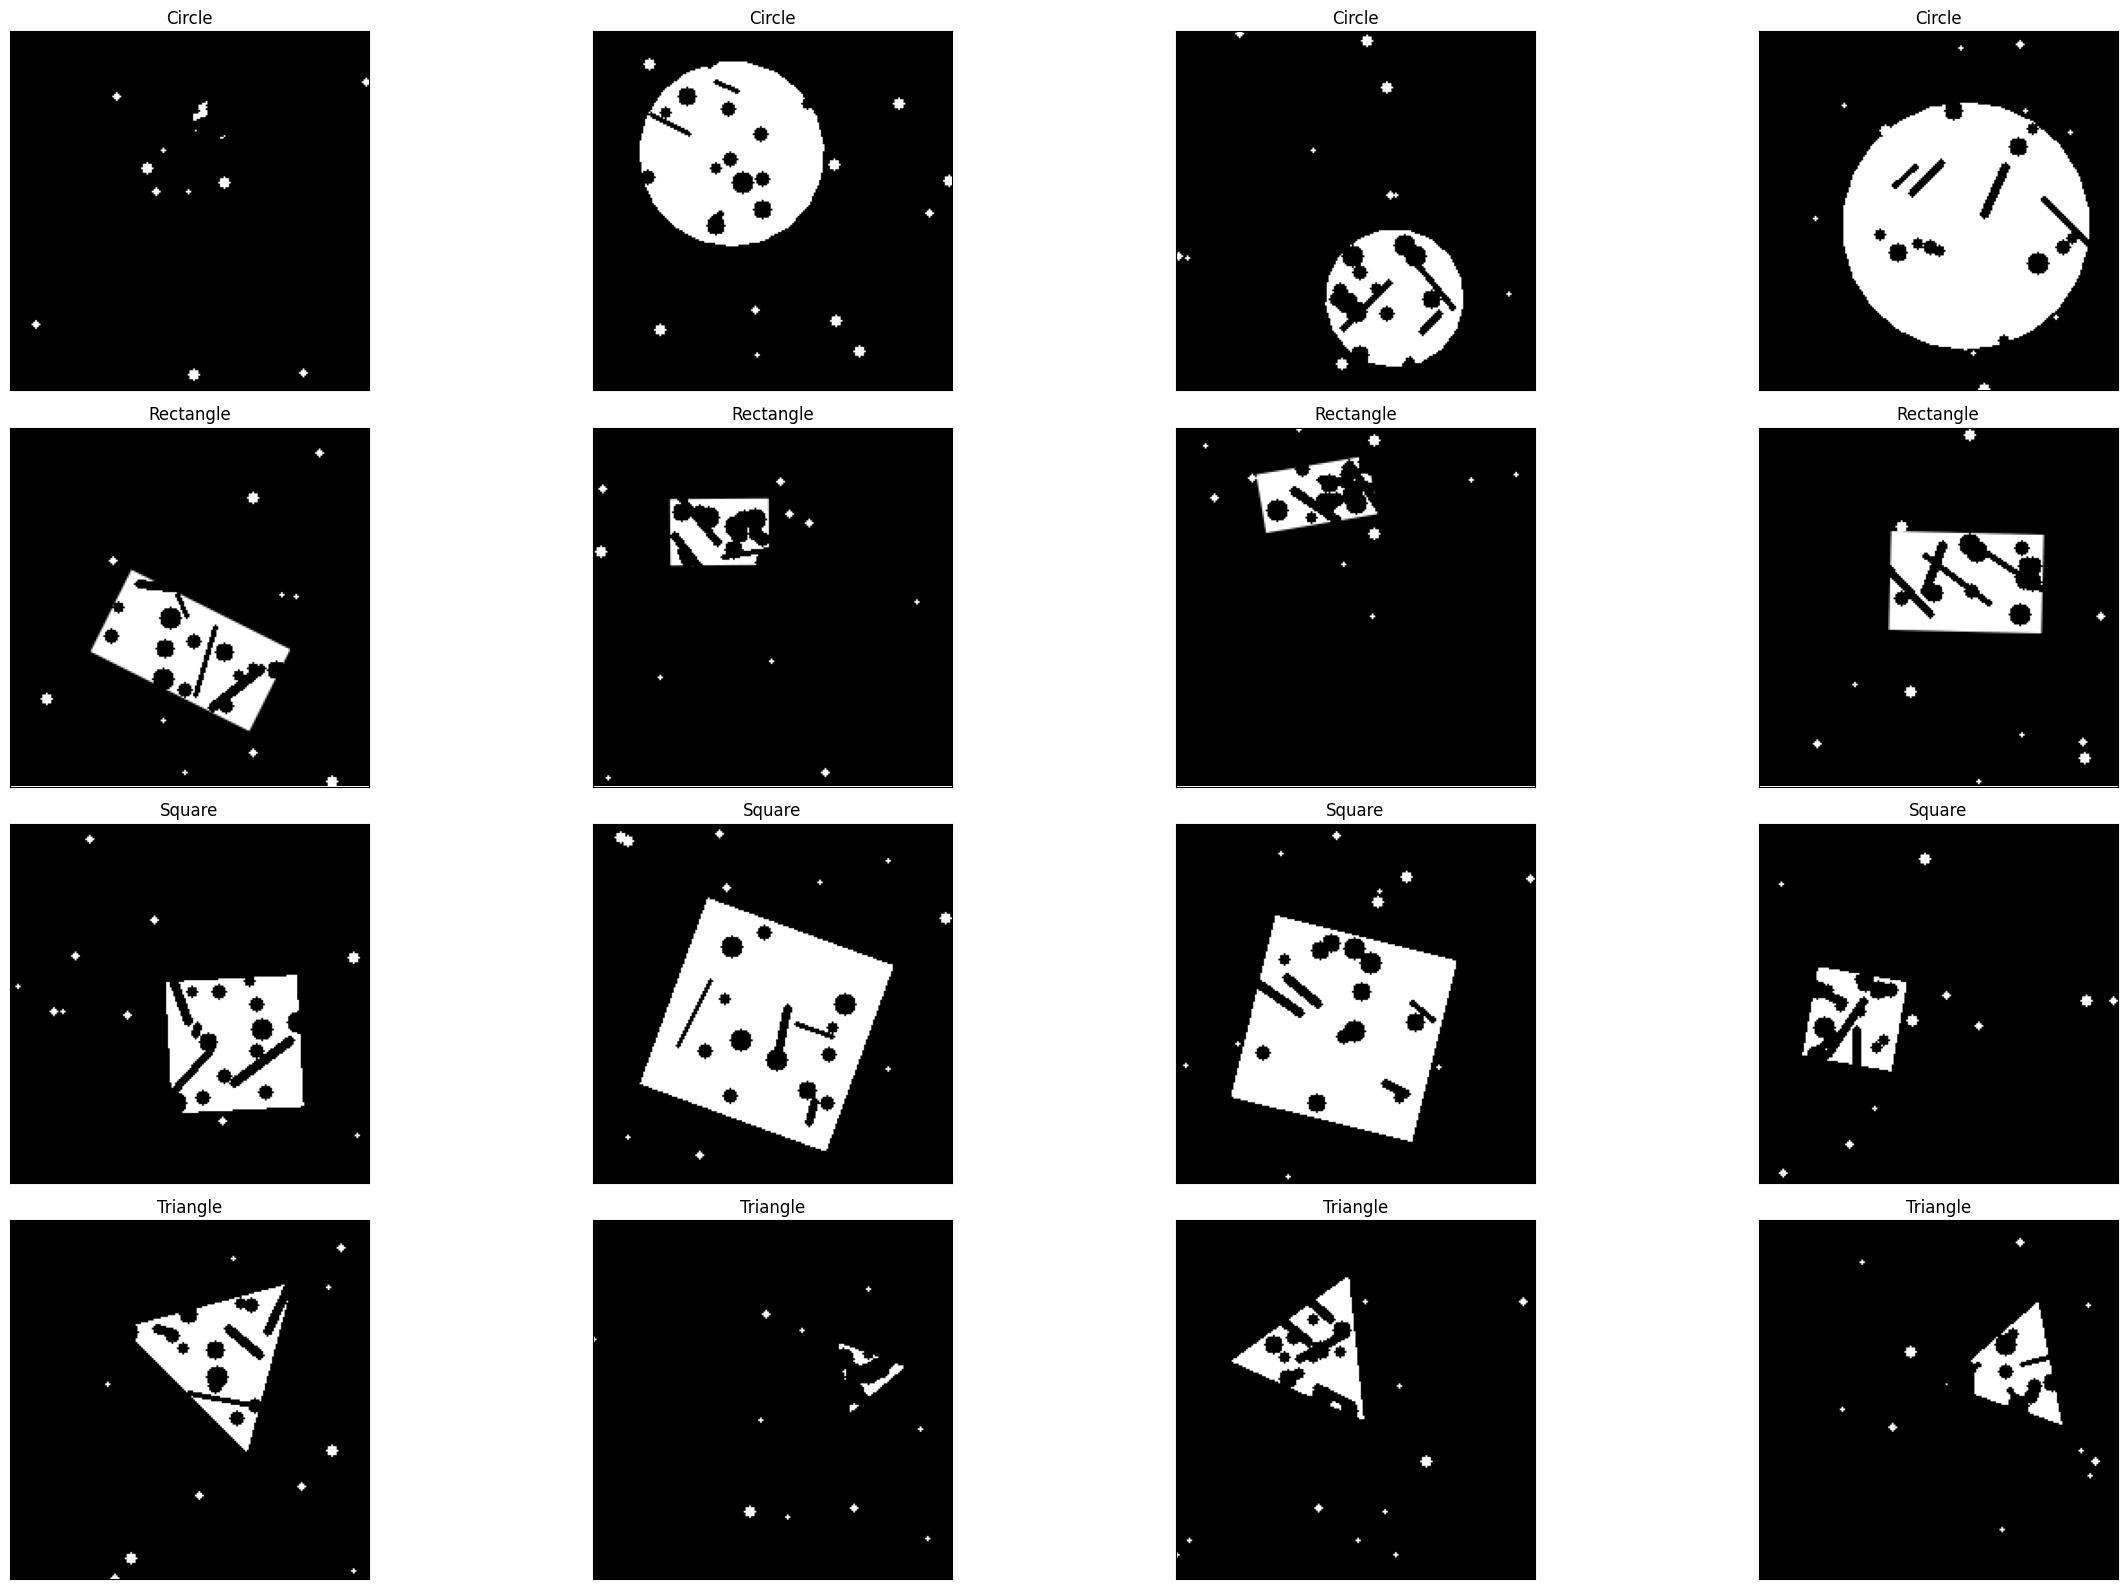

In [ ]:
show_samples(noise_pictures)

Iz prikaza se vidi kako je uspješno simuliran šum te slike samim time više nisu idealne i zahtijevaju dodatnu obradu prije pronaaska kontura i klasifikacije.

In [ ]:
def closing(noise_pictures):
  closing_pictures = []
  kernel = cv.getStructuringElement(cv.MORPH_RECT, (5, 5))

  for i in range(len(noise_pictures)):
     closing_img = noise_pictures[i].copy()

     closing_img = cv.morphologyEx(closing_img, cv.MORPH_CLOSE, kernel, iterations=3)


     closing_pictures.append(closing_img)

  return closing_pictures


closing_pictures = closing(noise_pictures)




Definirana je funkcija closing() koja kao parametar prima listu slika. Iterativnim prolaskom kroz svaku sliku primjenjuje se morfološka operacija zatvaranja MORPH_CLOSE, koristeći kernel pravokutnog oblika veličine 5x5, u 3 iteracije.

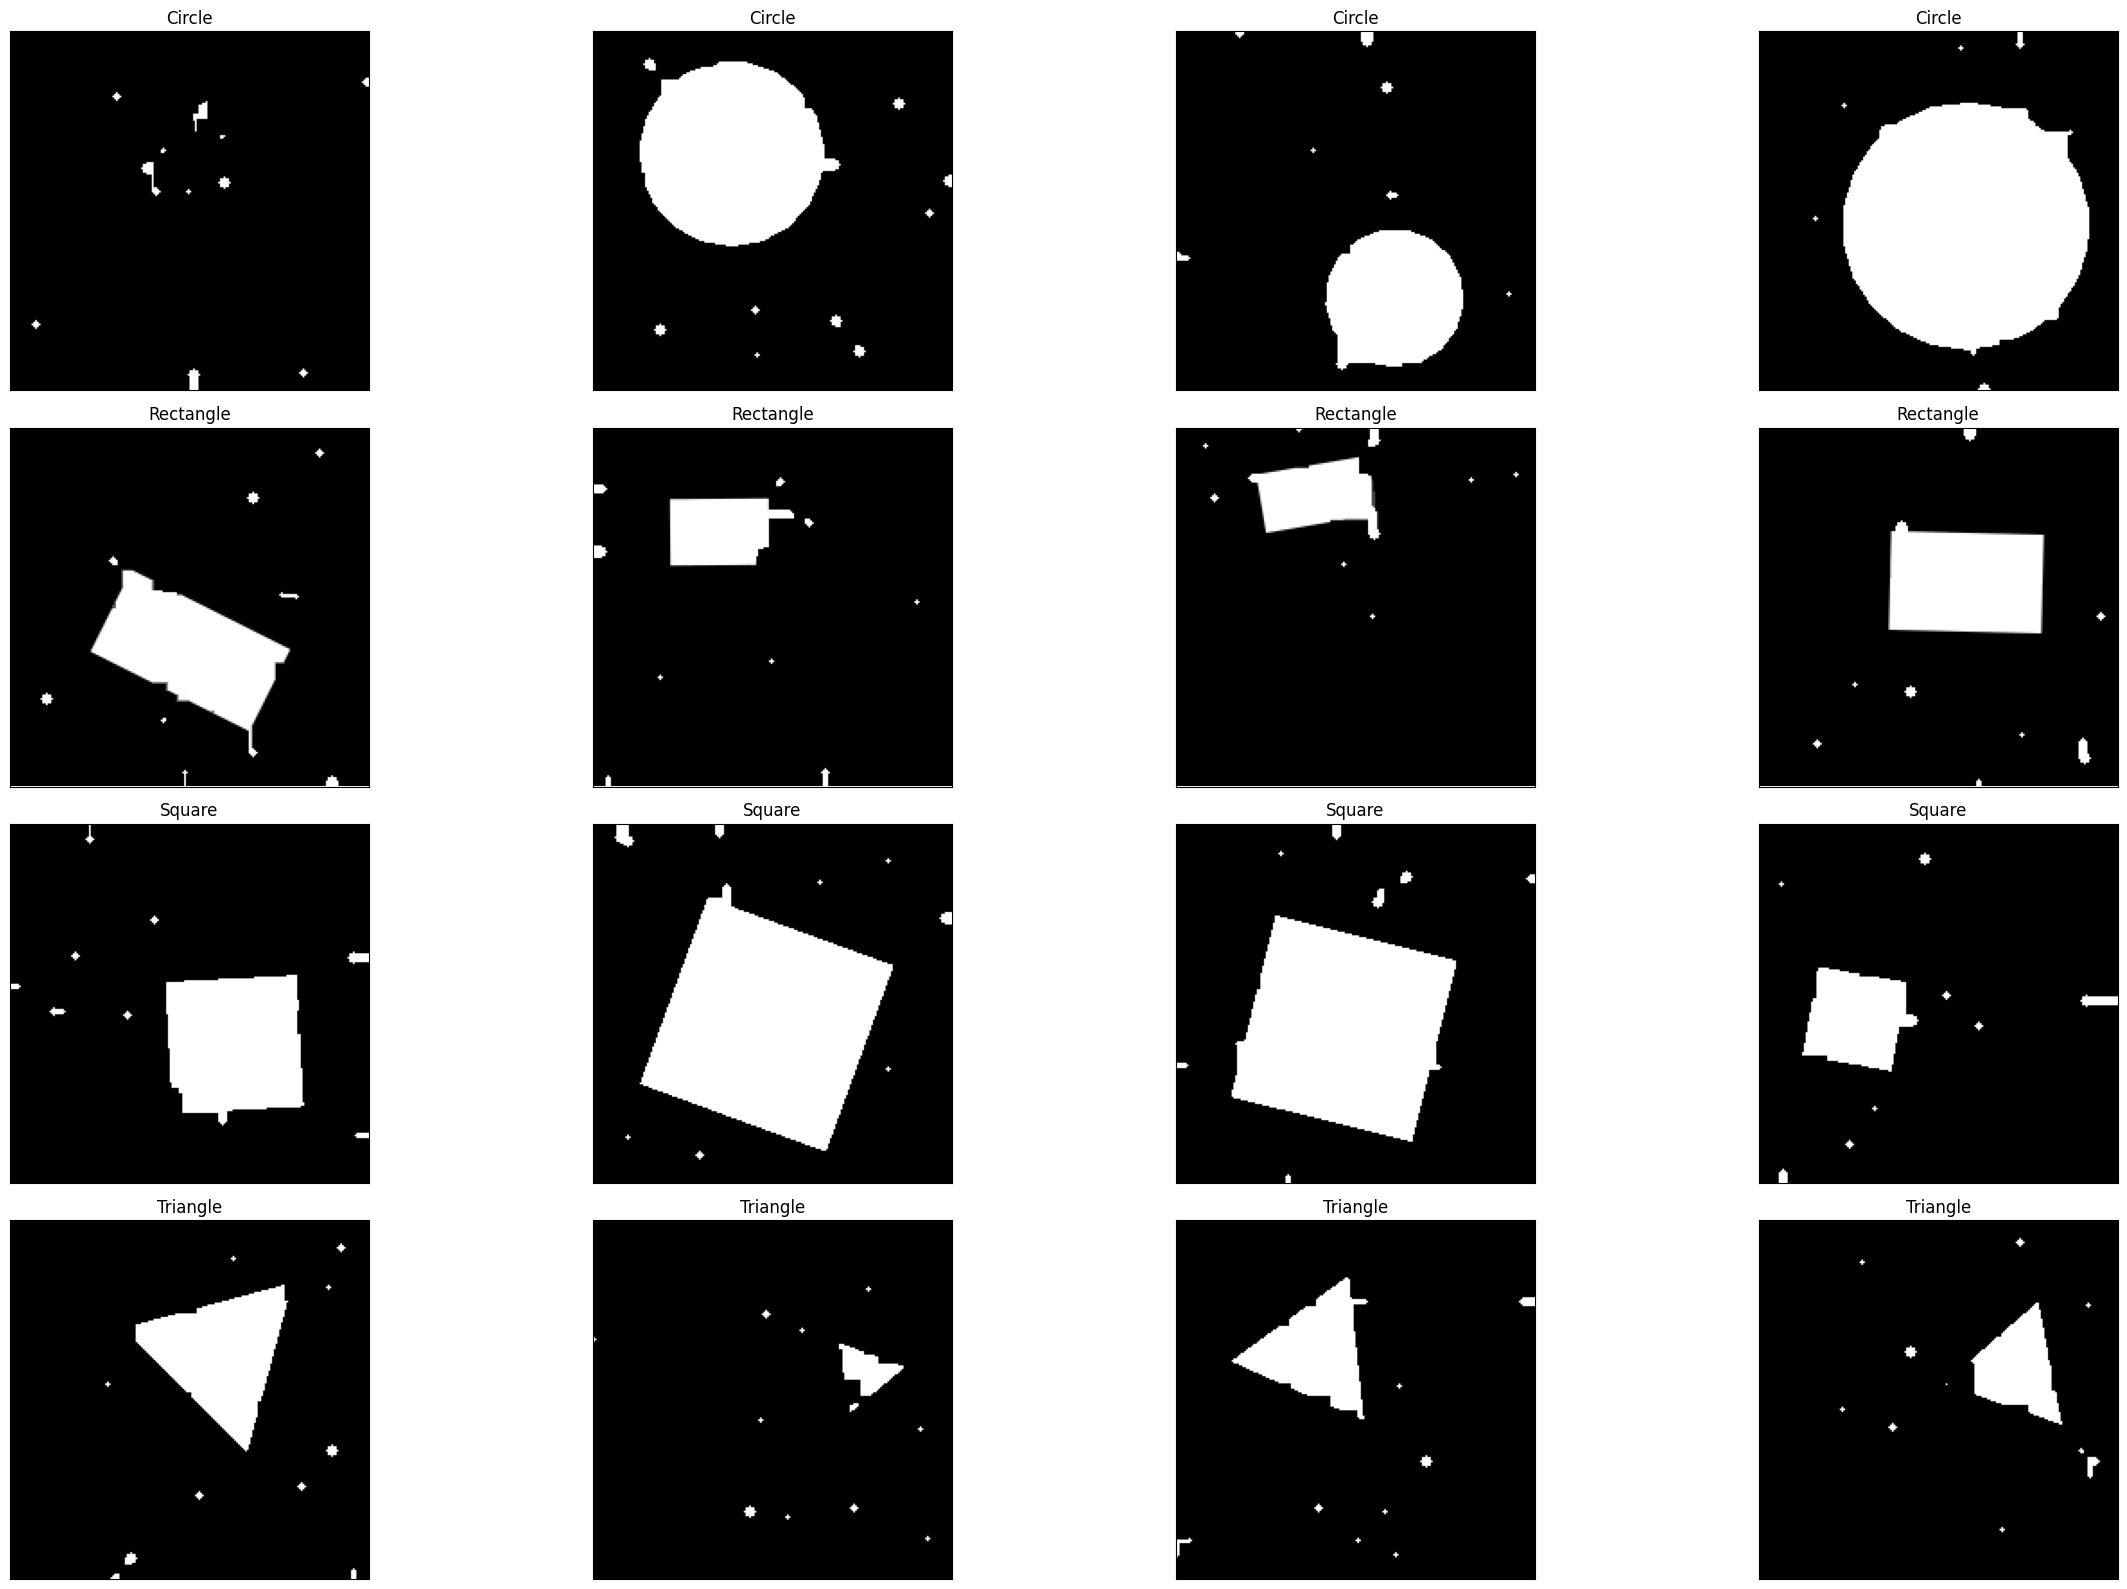

In [ ]:
show_samples(closing_pictures)

Iz slika se vidi kako su rupe u geometrijskim oblicima popunjene primjenom morfološke operacije zatvaranja.

In [ ]:
def opening(closing_pictures):
  opening_pictures = []
  kernel = cv.getStructuringElement(cv.MORPH_RECT, (5, 5))

  for i in range(len(closing_pictures)):
     opening_img = closing_pictures[i].copy()

     opening_img = cv.morphologyEx(opening_img, cv.MORPH_OPEN, kernel, iterations=2)


     opening_pictures.append(opening_img)

  return opening_pictures


opening_pictures = opening(closing_pictures)



Definirana je funkcija opening() koja prima prethodno obrađene slike operacijom zatvaranja. Nad njima se primjenjuje morfološka operacija otvaranja MORPH_OPEN koristeći isti oblik i veličinu kernela 5x5, ali s 2 iteracije.

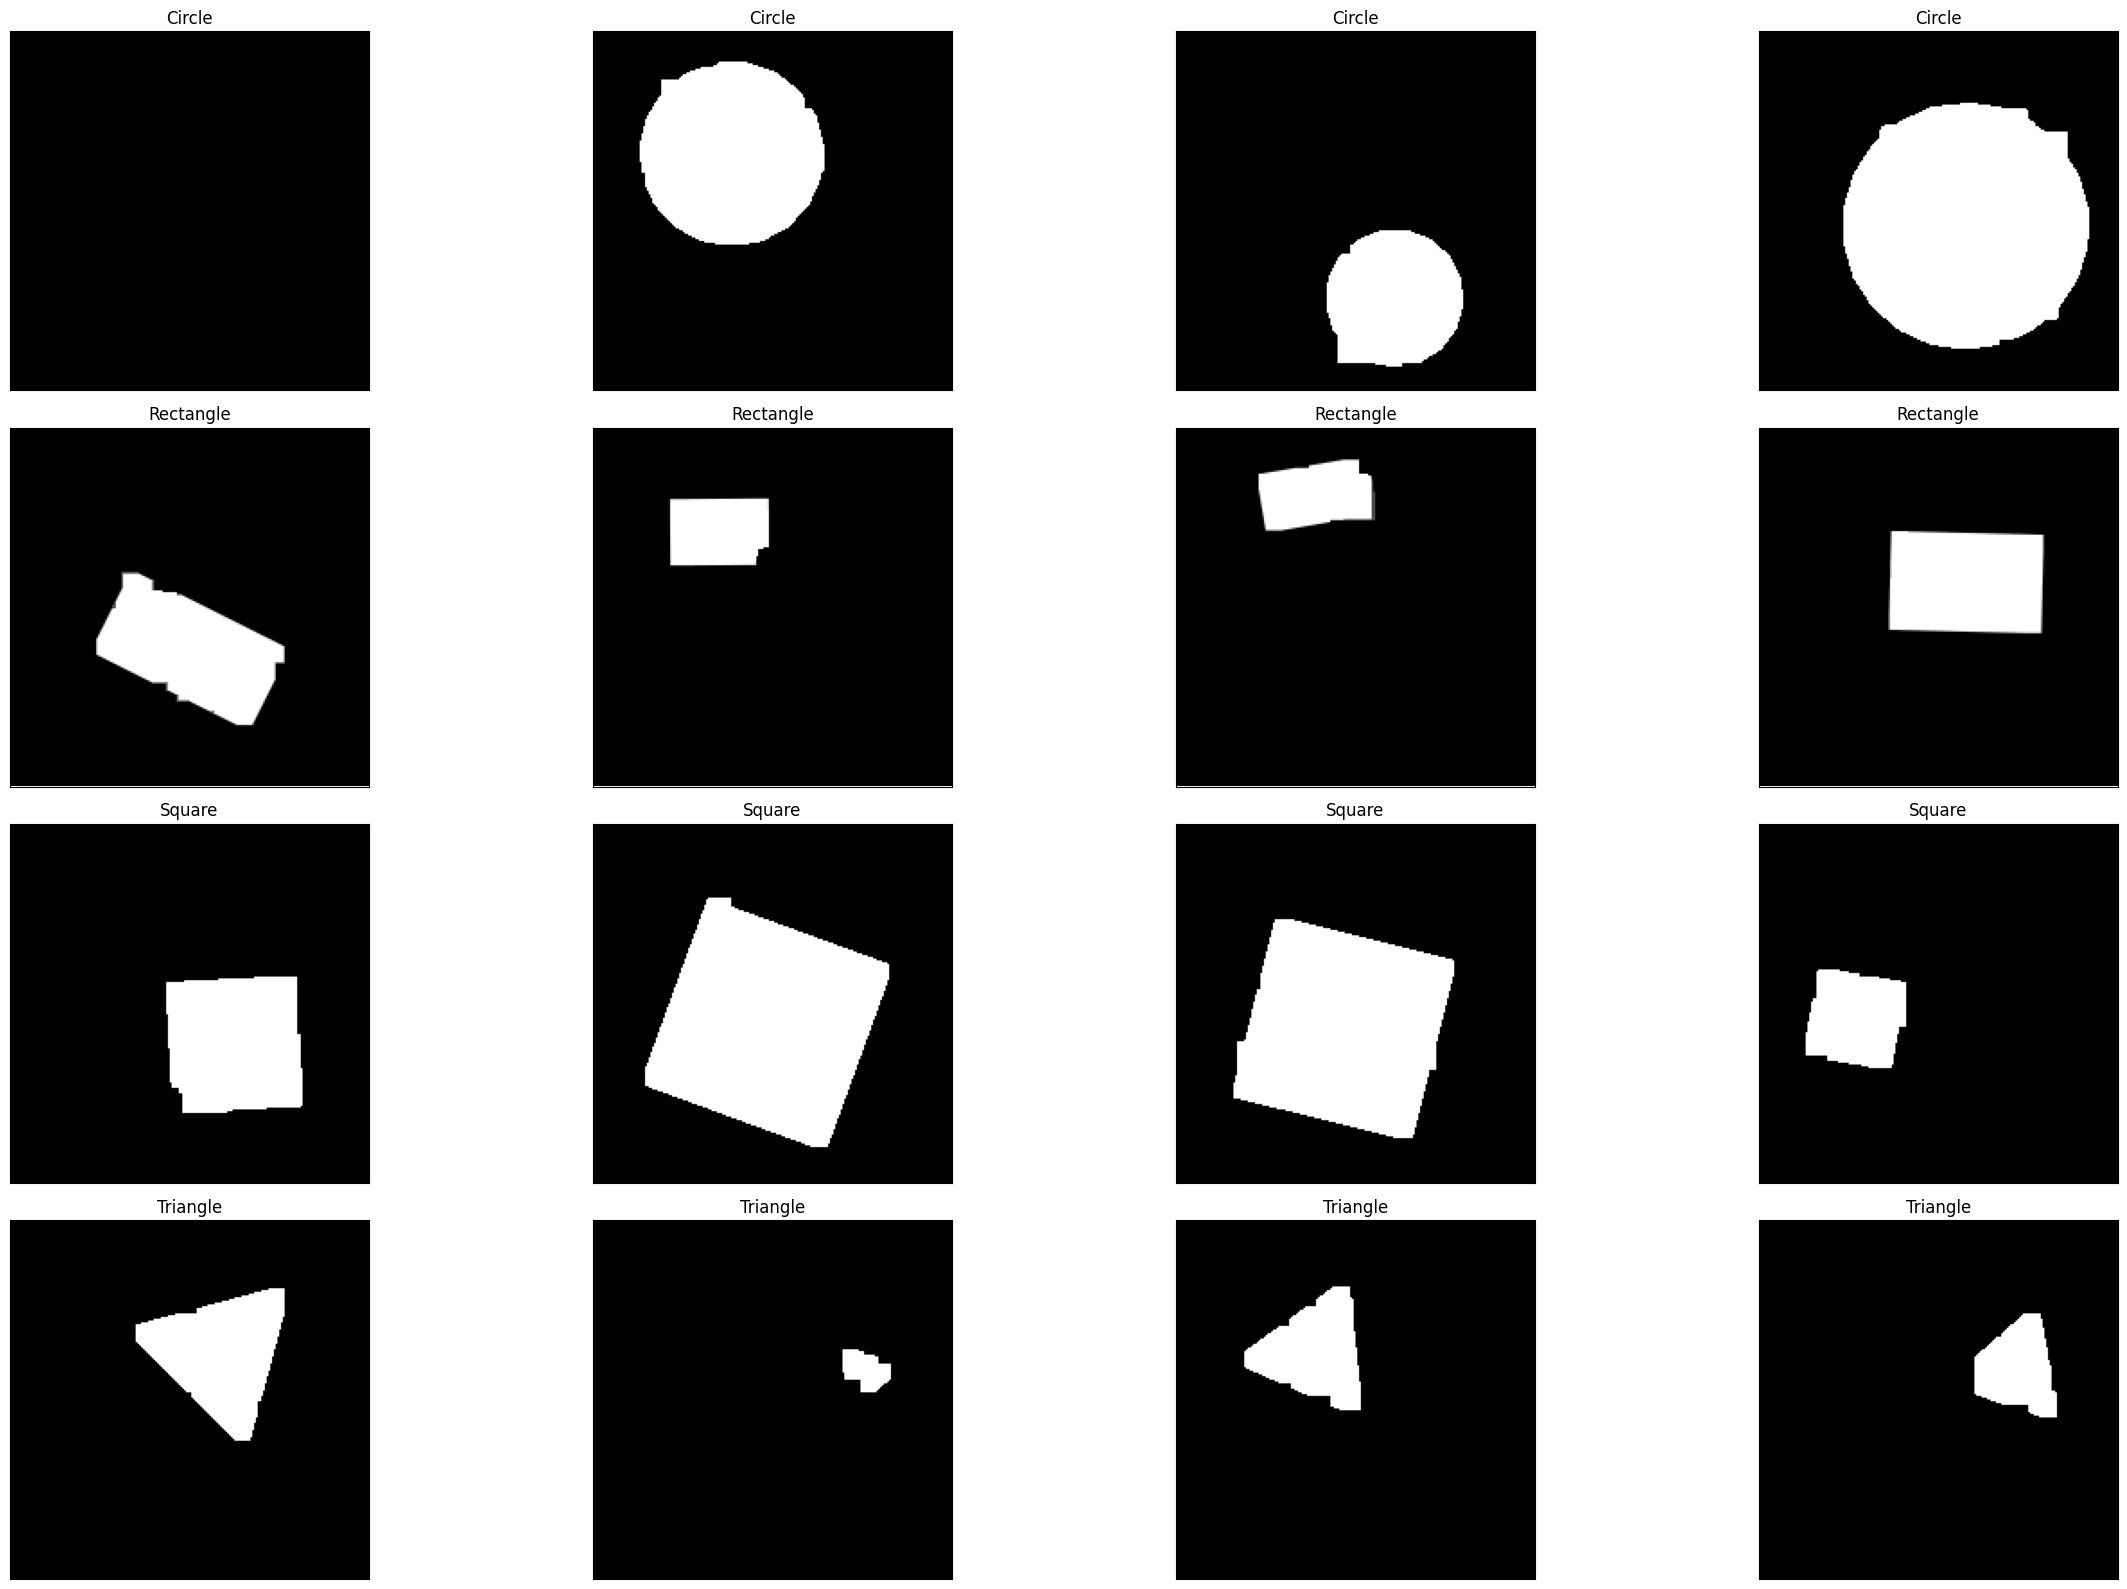

In [ ]:
show_samples(opening_pictures)

Iz vizualnog prikaza slika nakon primjene morfološke operacije otvaranja uspješno su uklonjene bijele točke u pozadini. Time je prikazan kako morfološka operacija može učinkovito otkloniti sitne šumove u pozadini.

In [ ]:
def findingcontours(pictures):

  podaci_kontura = []

  for i in range(len(pictures)):
    contours, _ = cv.findContours(pictures[i], cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)


    if contours:

      contours = max(contours, key=cv.contourArea)

      opseg = cv.arcLength(contours, True)
      aproksimacija = cv.approxPolyDP(contours, 0.04 * opseg, True)
      broj_vrhova = len(aproksimacija)

      (x_c, y_c), (w, h), angle = cv.minAreaRect(aproksimacija)
      aspect_ratio = max(w, h) / float(min(w, h)) if min(w, h) != 0 else 0

      area = cv.contourArea(contours)
      circularity = (4 * np.pi * area) / (opseg ** 2) if opseg > 0 else 0


      podaci_slike = {
                'broj_vrhova': broj_vrhova,
                'kontura_bodovi': aproksimacija,
                'aspect_ratio': aspect_ratio,
                'circularity': circularity
            }

    else:
      podaci_slike = {
            'broj_vrhova': 0,
            'kontura_bodovi': None,
             'aspect_ratio': 0,
            'circularity': 0
            }

    podaci_kontura.append(podaci_slike)


  return podaci_kontura










Definirana je funkcija za pronalaženje kontura geometrijskih oblika na slikama pomoću cv.findContours, pri čemu se uzimaju u obzir samo vanjske konture RETR_EXTERNAL iz razloga što unutrašnjost oblika nije bitna za njihovo prepoznavanje. Ako je na slici pronađeno više kontura, odabire se ona s najvećom površinom kako bi se osiguralo da se uzima u obzir glavni objekt na slici a ne šumovi.

Nakon pronalaska konture izračunat je njezin opseg pomoću cv.arcLength. Na osnovu opsega primjenom funkcije cv.approxPolyDP provedena je aproksimacija konture kojom se smanjuje broj točaka konture na minimalan broj koji i dalje dovoljno dobro opisuje geometrijski oblik.

Iz dobivene aproksimacije konture uzet je konačan broj vrhova.
Funkcijom cv.minAreaRect pronađen je najmanji rotirani pravokutnik koji u potpunosti omeđuje konturu. Nakon toga izračunat je omjer dimenzija te kružnost koja je bitna za klasifikaciju kruga.
Za svaku sliku rezultati se spremaju u rječnik koji sadrži broj vrhova, točke aproksimirane konture, omjer dimenzija i kružnost. Zatim se svi rezultati spremaju u listu podaci_kontura koja se koristi za daljni rad.

In [ ]:
noise_contours = findingcontours(noise_pictures)
morph_contours = findingcontours(opening_pictures)

U ovome djelu je pozvana funkcija za pronalazak kontura i dodatni parametara za klasifikaciju nad slikama sa šumom i nad slikama nad kojima su primjenjene morfološke operacije otvaranja i zatvaranja.

In [ ]:
def clasify(podaci_kontura):

  predictions = []

  for i in range(len(podaci_kontura)):

    broj_vrhova = podaci_kontura[i]['broj_vrhova']
    aspect_ratio = podaci_kontura[i]['aspect_ratio']
    circularity = podaci_kontura[i]['circularity']

    if broj_vrhova == 3:
      shape = "Triangle"
    elif circularity > 0.80:
      shape = "Circle"
    elif 4 <= broj_vrhova <= 8:
      if 0.85 <= aspect_ratio <= 1.15:
        shape = "Square"
      else:
        shape = "Rectangle"
    else:
      shape = "Unknown"

    predictions.append(shape)

  return predictions






Definirana je funkcija za klasifikaciju geomterijski oblika u kojoj se prvo učitavaju prethodno spremljeni parametri uzimajući odgovarajući rezultat svakog parametra preko indeksa slike. Nakon učitavanja rezultata provedena je odluka za klasifikaciju gdje se prvo provjerava broj vrhova. Ako je broj vrhova jednak 3 onda se geometrijski oblikklasificira kao trokut a ako nije ide daljna provjera gdje se gleda kruznost ako rezultata kruznosti zadovoljava defnirani prag koji je 0.80 onda se klasificira kao krug. Prag je postavljen na temelju toga što kružnot kruga je veća u odnosu na druge geometrijske oblike i bliža je broju 1. Ako nije ni ispunjen uvjet kruznosti provjeravaju se omjeri dimenzija stranica ali uz uvjet da je broj vrova između 4 i 8. Razlog je u tome sto sumovi su narusili geomtrijske oblike i doveli da ima vise vrihoav oz toga razloag sam definirao raspon. Ako niti jedna od uvjeta nije ispunjen postavljeno je da onda slika bude klaificirana kao nepoznato.

In [ ]:
predictions_noise = clasify(noise_contours)
predictions_morph = clasify(morph_contours)

Ovdje je pozvana funkcija za klasifikaciju nad slikama sa šumom i slikama nad kojima su primjenjene morfološke operacije kako bi se smanjio negativan utjecaj šuma.

In [ ]:
print(labels[0])
print(predictions_noise[0])
print(predictions_morph[0])

Circle
Rectangle
Unknown


Ovdje je uzet jedan uzorak koji je bio kategorije Krug te su predikcije kod sliak sa šumom i slika s dodatno primjenenim morfološkim operacijama bile pogrešne.

In [ ]:
y_true = np.array(labels)
y_pred_noise = np.array(predictions_noise)
y_pred_morph = np.array(predictions_morph)

accuracy_noise = (np.sum(y_true == y_pred_noise) / len(pictures)) * 100
accuracy_morph = (np.sum(y_true == y_pred_morph) / len(pictures)) * 100
print(f"Ukupna točnost nad slikama sa šumom je: {accuracy_noise:.2f}% ")
print(f"\nUkupna točnost nad slikama sa morfološkim operacijama je: {accuracy_morph:.2f}% ")



Ukupna točnost nad slikama sa šumom je: 51.67% 

Ukupna točnost nad slikama sa morfološkim operacijama je: 77.50% 


U ovom dijelu koda provedena je evaluacija točnosti klasifikacije oblika, i to zasebno za slike sa šumom i za slike nad kojima su primijenjene morfološke operacije.

Točnost je izračunata kao omjer broja ispravno klasificiranih slika i ukupnog broja slika pomnožena sa 100 kako bi se dobio postotak.

In [ ]:
def category_accuracy(y_true, y_pred):
  for category in maps:

    true_predictions = (y_true == category)

    count_true = np.sum(true_predictions)

    if count_true > 0:
      true_classified = np.sum((y_true == category) & (y_pred == category))


      category_accuracy = (true_classified / count_true) * 100

      print(f"{category:<10} -> {category_accuracy:.2f}% ({true_classified}/{count_true})")







category_accuracy(y_true, y_pred_noise)
print("")
category_accuracy(y_true, y_pred_morph)




Circle     -> 6.67% (2/30)
Rectangle  -> 90.00% (27/30)
Square     -> 83.33% (25/30)
Triangle   -> 26.67% (8/30)

Circle     -> 76.67% (23/30)
Rectangle  -> 100.00% (30/30)
Square     -> 80.00% (24/30)
Triangle   -> 53.33% (16/30)


Kako bi se dobio bolji uvid u točnost klasifikacije  definirana je funkcija category_accuracy koja izračunava točnost zasebno za svaku kategoriju.

Iz rezulatat se vidi kako su morofloške operacije znatno povećale točnost klasifikacije pa je tako na primjer krug koji je samo 6 posto točnosti klasificiran kod slika sa šumom stigao do točnosti od 76 posto nakon primjene morfološki operacija zatvaranja i otvaranja nad slikama sa šumom.

In [ ]:
def show_contours(podaci_kontura, maps, predictions):
  num_categories = len(maps)
  fig, axes = plt.subplots(num_categories, 3, figsize=(11, 11))

  for row_idx, category in enumerate(maps):

      indeksi = [i for i in range(len(labels)) if labels[i] == category]

      for col_idx in range(3):
          ax = axes[row_idx, col_idx]
          idx = indeksi[col_idx]

          slika = pictures[idx]
          slika_boja = cv.cvtColor(slika, cv.COLOR_GRAY2RGB)

          aproks = podaci_kontura[idx]['kontura_bodovi']
          vrhovi = podaci_kontura[idx]['broj_vrhova']

          predicted = predictions[idx]

          if aproks is not None:
              cv.drawContours(slika_boja, [aproks], -1, (0, 102, 204), 2)
              for bod in aproks:
                  x, y = bod.ravel()
                  cv.circle(slika_boja, (x, y), 5, (0, 255, 0), -1)

          ax.imshow(slika_boja)

          color = 'green' if predicted == category else 'red'

          ax.set_title(f"")
          ax.set_title(f"Stvarno: {category}\nPredviđeno: {predicted}\n vrhova: {vrhovi}",
                        color=color, fontsize=9)
          ax.axis('off')


  plt.suptitle("Detekcija oblika s konturama", fontsize=14)
  plt.tight_layout()
  plt.show()

Definirana je funkcija za vizualni prikaz rezultata detekcije kontura i klasifikacije oblika.

In [ ]:
def show_process(maps):
  num_categories = len(maps)
  fig, axes = plt.subplots(num_categories, 4, figsize=(12, 9))

  for row_idx, category in enumerate(maps):
      indeksi = [i for i in range(len(labels)) if labels[i] == category]
      idx = indeksi[0]

      original = pictures[idx]
      noise = noise_pictures[idx]
      closing = closing_pictures[idx]
      opening = opening_pictures[idx]

      axes[row_idx, 0].imshow(original, cmap='gray')
      axes[row_idx, 0].set_title(f'Original - {category}')
      axes[row_idx, 0].axis('off')

      axes[row_idx, 1].imshow(noise, cmap='gray')
      axes[row_idx, 1].set_title('Noise')
      axes[row_idx, 1].axis('off')

      axes[row_idx, 2].imshow(closing, cmap='gray')
      axes[row_idx, 2].set_title('Closing')
      axes[row_idx, 2].axis('off')

      axes[row_idx, 3].imshow(opening, cmap='gray')
      axes[row_idx, 3].set_title('Opening')
      axes[row_idx, 3].axis('off')


  plt.suptitle("Prikaz primjena morfoloski operacija", fontsize=14)
  plt.tight_layout()
  plt.show()











U ovome dijelu je definrana funkcija za prikaz procesa obrade slike.

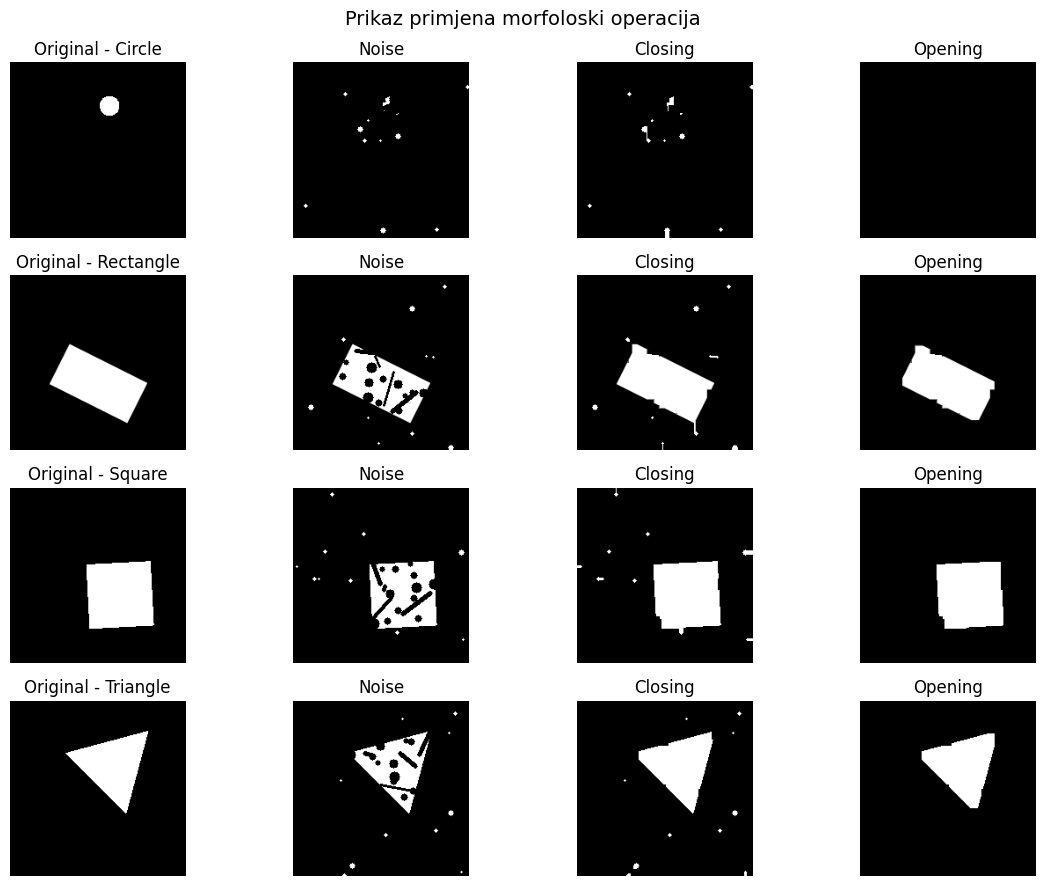

In [ ]:
show_process(maps)

Iz vizualnog prikaza idljivo je kako su morfološke operacije zatvranja i otvaranja pomogle ali šumovi su imali negativan utjecaj pogotovo kod geometrijskih oblika manjih dimenzija koji se nestali nakon primejne morfološki operacija iz razloga što im je šum narušio strukturu u velikoj mjeri.

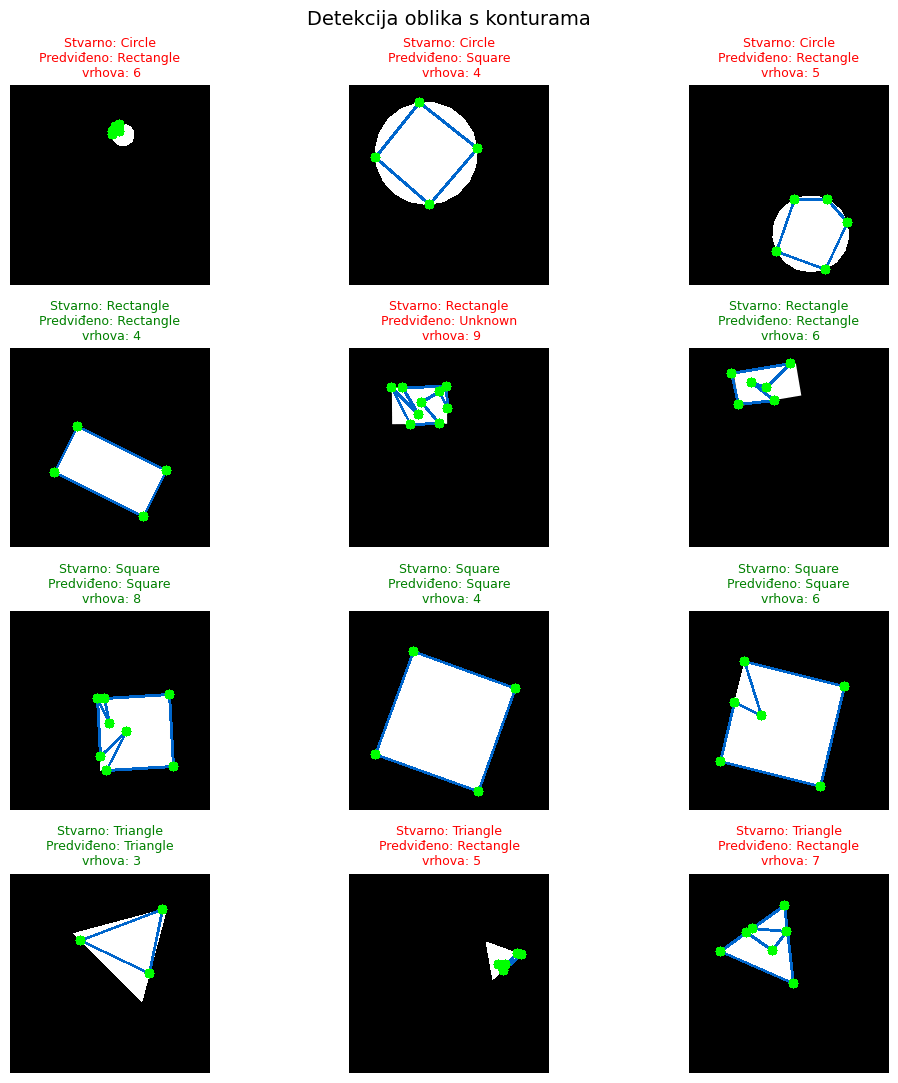

In [ ]:
show_contours(noise_contours, maps, predictions_noise)

U ovome dijelu su prikazane vizualno konture i predikcije od slika sa šumom.

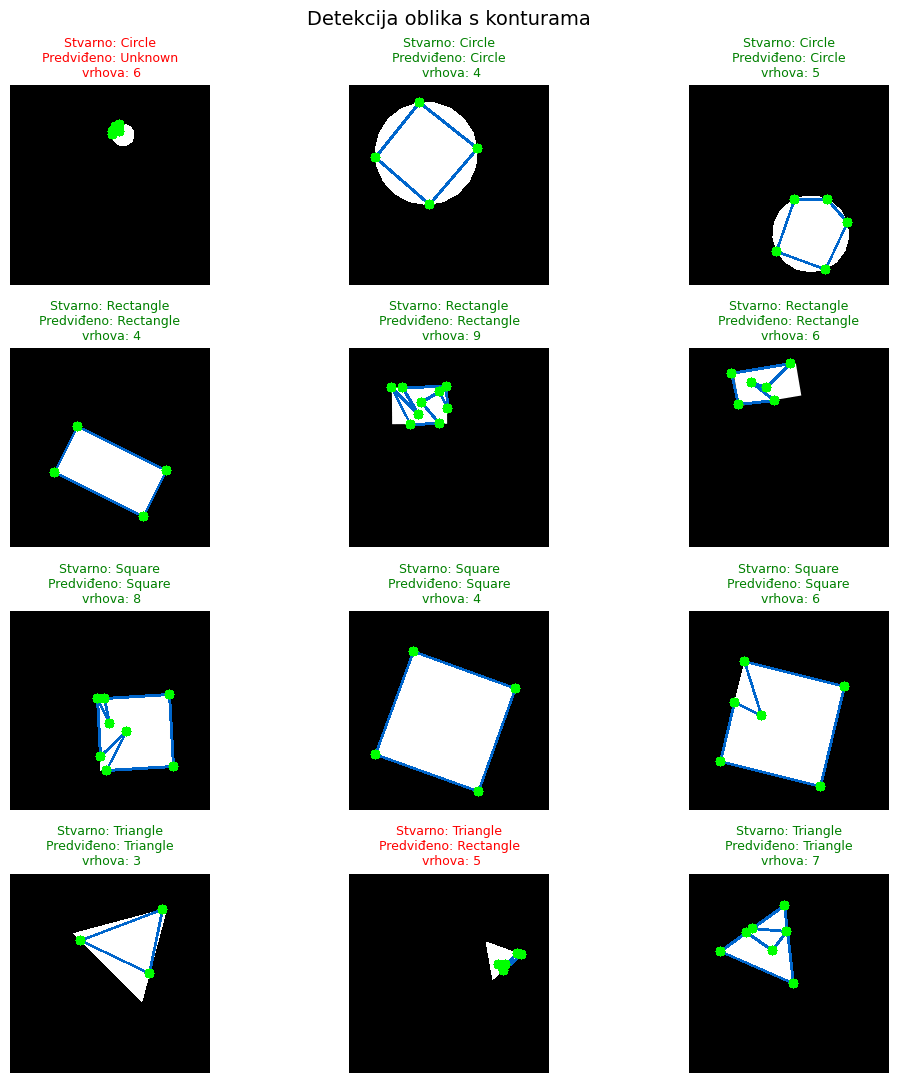

In [ ]:
show_contours(noise_contours, maps, predictions_morph)

U ovome dijelu su prikazane vizalno konture i predikcije od slika sa šumom ali nad kojima su primjennjene morfološkeoperacije zatvranja i otvaranja.

In [ ]:
original_shape = findingcontours(pictures)
predictions_original = clasify(original_shape)


U ovome dijelu su pozvane funkcije za pronalazak kontura i klasifikaciju nad slikama bez šuma.

In [ ]:

y_pred_original = np.array(predictions_original)


accuracy_noise = (np.sum(y_true == y_pred_original) / len(pictures)) * 100

print(f"Ukupna točnost nad slikama bez šuma: {accuracy_noise:.2f}% ")


Ukupna točnost nad slikama bez šuma: 99.17% 


In [ ]:
category_accuracy(y_true, y_pred_original)

Circle     -> 100.00% (30/30)
Rectangle  -> 100.00% (30/30)
Square     -> 96.67% (29/30)
Triangle   -> 100.00% (30/30)


Nakon evaluacije ukupne točnosti te točnosti po klasama se vidi kako je sustav za klasifikaciju primjenom klasični metoda računalnoga vida s visokom točnošću klasificirao sve geometrijske oblike.

In [ ]:
closing_pictures = closing(pictures)
original_erode = opening(closing_pictures)

U ovome dijelu su pozvane funkcije otvaranja i zatvranja odnosno pirmjenite su morfološke operacije otvaranja i zatvaranja nad idealnim slikama bez šuma.

In [ ]:
original_shapes = findingcontours(original_erode)
predictions_original_e = clasify(original_shapes)


y_pred_original_e = np.array(predictions_original_e)


accuracy_noise = (np.sum(y_true == y_pred_original_e) / len(pictures)) * 100

print(f"Ukupna točnost nad slikama bez šuma: {accuracy_noise:.2f}% ")

category_accuracy(y_true, y_pred_original_e)


Ukupna točnost nad slikama bez šuma: 86.67% 
Circle     -> 100.00% (30/30)
Rectangle  -> 90.00% (27/30)
Square     -> 83.33% (25/30)
Triangle   -> 73.33% (22/30)


Iz rezultata se vidi kako je točnost pala nakon primjena morofloški operacija otvaranja i zatvranja nad slikama bez šuma.

In [ ]:
def wrong_pred(predictions, maps, final_pictures):

    fig_idxs = []

    for category in maps:
        indeksi = [i for i in range(len(labels)) if labels[i] == category and predictions[i] != category]
        fig_idxs.extend(indeksi[:3])

    if len(fig_idxs) == 0:
        print("Nema pogrešnih predikcija.")
        return

    fig, axes = plt.subplots(len(fig_idxs), 3, figsize=(8, len(fig_idxs) * 3))

    if len(fig_idxs) == 1:
        axes = np.array([axes])

    for i, idx in enumerate(fig_idxs):

        axes[i, 0].imshow(original_pictures[idx])
        axes[i, 0].set_title(f"Stvarno: {labels[idx]} \n Predviđeno:{predictions[idx]}")
        axes[i, 0].axis('off')

        axes[i, 1].imshow(pictures[idx], cmap='gray')
        axes[i, 1].set_title(f"Nakon Otsu treshold")
        axes[i, 1].axis('off')

        axes[i, 2].imshow(final_pictures[idx], cmap='gray')
        axes[i, 2].set_title(f"Konačni izgled: {labels[idx]}")
        axes[i, 2].axis('off')




    plt.suptitle("Pogresno klasificirani oblici", fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()

Definirana je funkcija kojom se uzimaju pogrešne predikcije i to po 3 pogrešne predikcije za svaku kategoriju naravno ako ima toliko pogrešni predikcija i zatim se prikazuju originalna slika koja je u boji, binarizirana slika i konačna slika nako svih obrada.

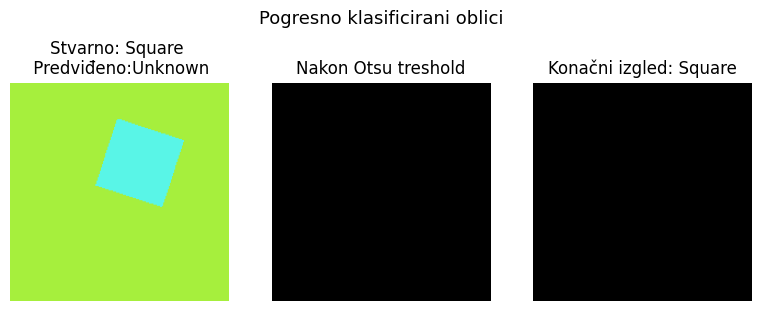

In [ ]:
wrong_pred(y_pred_original, maps, pictures)

Kod porešne predikcije idealnih slika bez šuma imamo samo jednu pogrešnu predikciju kvadrata. Razlog je što pretvorbom slike iz RGB U Grayscale slika je postala jedne boje iz razloga što su kavdrat i pozadina bili vrlo sličnoga kontrasta.

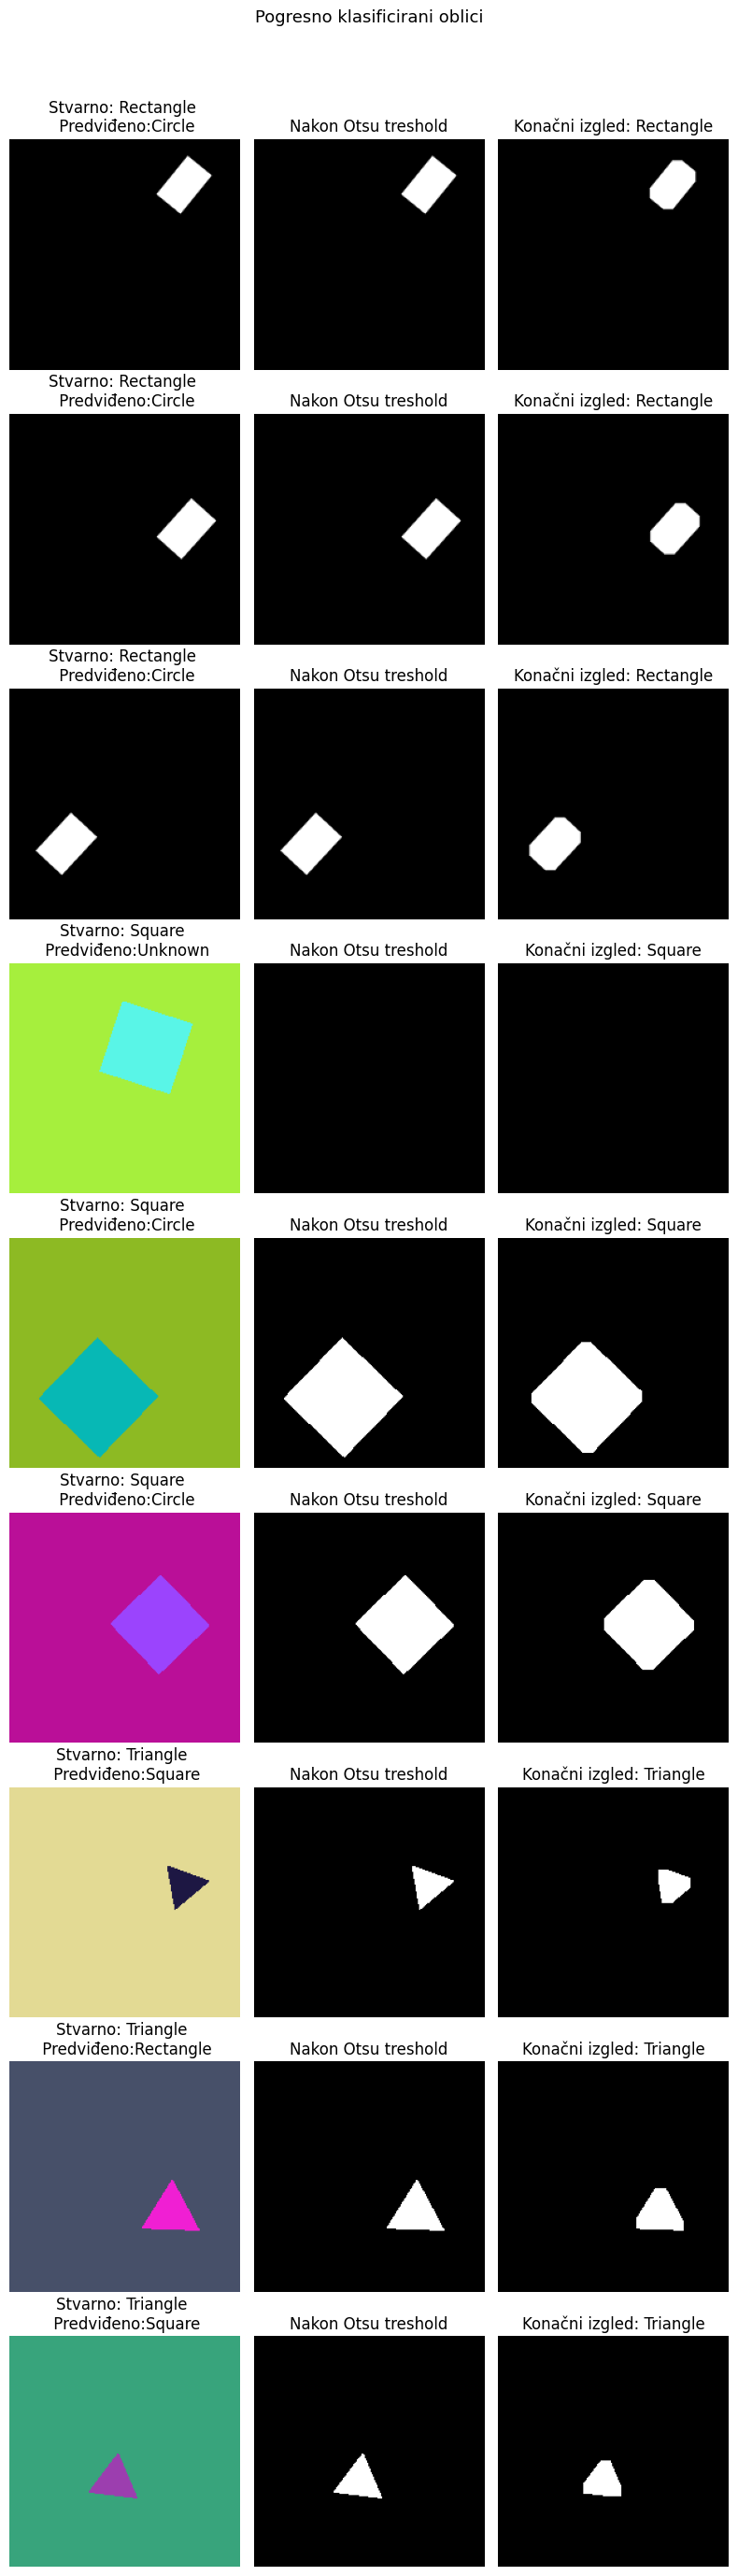

In [ ]:
wrong_pred(y_pred_original_e, maps, original_erode)

U ovome dijelu je prikazana pogrešna predikcija slika bez šuma ali nad kojima su primjenjene morfoološke operacije zatvranja o otvranja. Iz prikaza se vidi kako postavke morofloški operacija zatvaranja i otvaranja koje pomažu smanjiti nepravilnosti oblika nastali zbog šuma kod slika bez šuma su imali negativan utjecaj tako što su vrhovi zaobljeni.